In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/smart-mcq-solver-challenge/sample_submission.csv
/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv
/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv


In [2]:
# ── CELL 1 : Env var BEFORE any CUDA call ───────────────────
import os
os.environ['PYTORCH_ALLOC_CONF'] = 'expandable_segments:True'

!pip install -q transformers==4.40.0 accelerate==0.29.3 wandb datasets sentencepiece lightgbm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.6/137.6 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.0/9.0 MB 72.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 297.6/297.6 kB 20.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 33.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 94.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.2/12.2 MB 95.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dask-cuda 26.2.0 requires cuda-core==0.3.*, but you have cuda-core 1.0.1 which is incompatible.
dask-cuda 26.2.0 requires numba-cuda<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
distributed-ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
sentence-transforme

In [3]:
# ── CELL 2 : Imports ────────────────────────────────────────
import os, gc, random, warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import (
    AutoTokenizer,
    AutoModelForMultipleChoice,
    get_cosine_schedule_with_warmup,
    get_linear_schedule_with_warmup,
)
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score
from sklearn.feature_extraction.text import TfidfVectorizer
import wandb
from tqdm.auto import tqdm
from dataclasses import dataclass
from typing import Dict, List, Optional
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')

SEED = 42
def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)

set_seed(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device : {DEVICE}')
if torch.cuda.is_available():
    print(f'GPU    : {torch.cuda.get_device_name(0)}')
    total_vram = torch.cuda.get_device_properties(0).total_memory / 1e9
    print(f'VRAM   : {total_vram:.1f} GB')

Device : cuda
GPU    : Tesla T4
VRAM   : 15.6 GB


In [4]:
# ── CELL 3 : Configuration ──────────────────────────────────
@dataclass
class CFG:
    # ── Paths ────────────────────────────────────────────────
    # Update the folder name to match your Kaggle dataset slug
    train_path : str = '/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv'
    test_path  : str = '/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv'
    sub_path   : str = '/kaggle/input/competitions/smart-mcq-solver-challenge/sample_submission.csv'
    output_dir : str = '/kaggle/working/'

    # ── WandB ────────────────────────────────────────────────
    wandb_project : str           = 'smart-mcq-solver'
    wandb_entity  : Optional[str] = None   # your WandB username / team

    # ── Model (overridden per experiment) ────────────────────
    model_name : str = 'roberta-large'
    num_labels : int = 5            # A B C D E

    # ── Training ─────────────────────────────────────────────
    # ⚠️ Memory-safe defaults for 15 GB T4 GPU
    # Automatically uses batch_size=2 and accum_steps=8 if T4x2 is detected
    batch_size   : int   = 2 if torch.cuda.device_count() > 1 else 1
    accum_steps  : int   = 8 if torch.cuda.device_count() > 1 else 16
    max_len      : int   = 256      # 256 safely fits 5×256 on 15 GB
    epochs       : int   = 4
    lr           : float = 1e-5
    weight_decay : float = 0.01
    warmup_ratio : float = 0.10
    scheduler    : str   = 'cosine'

    # ── Memory tricks ────────────────────────────────────────
    gradient_checkpointing : bool = True   # saves ~40% activation memory
    fp16                   : bool = True   # AMP; saves ~2× memory

    # ── Regularisation ───────────────────────────────────────
    dropout         : float = 0.10
    label_smoothing : float = 0.05

    # ── Inference ────────────────────────────────────────────
    top_k          : int = 3
    #infer_batch    : int = 2   # slightly larger batch OK for inference (no grads)
    infer_batch    : int = 4 if torch.cuda.device_count() > 1 else 2

cfg = CFG()
print("Config ready ✅")
print(f"  Effective batch : {cfg.batch_size} × {cfg.accum_steps} = {cfg.batch_size * cfg.accum_steps}")
print(f"  max_len         : {cfg.max_len}  →  5 × {cfg.max_len} = {5 * cfg.max_len} tokens per sample")

Config ready ✅
  Effective batch : 2 × 8 = 16
  max_len         : 256  →  5 × 256 = 1280 tokens per sample


In [5]:
# ── CELL 4 : Data Loading & EDA ─────────────────────────────
train_df = pd.read_csv(cfg.train_path)
test_df  = pd.read_csv(cfg.test_path)
sub_df   = pd.read_csv(cfg.sub_path)

print(f"Train : {train_df.shape}  |  Test : {test_df.shape}")
print(train_df.head(3).to_string())

OPTION_COLS  = ['A', 'B', 'C', 'D', 'E']
LABEL_TO_IDX = {opt: i for i, opt in enumerate(OPTION_COLS)}
IDX_TO_LABEL = {i: opt for opt, i in LABEL_TO_IDX.items()}

train_df['label'] = train_df['answer'].map(LABEL_TO_IDX)

print("\nAnswer distribution:")
print(train_df['answer'].value_counts())

train_df['prompt_len'] = train_df['prompt'].str.split().str.len()
print(f"\nPrompt word-length (95th pct = {train_df['prompt_len'].quantile(0.95):.0f} words):")
print(train_df['prompt_len'].describe().to_string())

Train : (2000, 8)  |  Test : (500, 7)
   id                                                                                                                                                                                  prompt                                                                                                                                                                                                                                                                                                                                                                                                                       A                                                                                                                                                                                                                                                                                                                                                                             

In [6]:
# ── CELL 5 : Dataset ────────────────────────────────────────
class MCQDataset(Dataset):
    """
    Returns tensors [5, max_len] for AutoModelForMultipleChoice.
    Uses 'longest' padding (not 'max_length') to avoid padding short
    sequences to the full max_len — saves ~30% memory on short inputs.
    """
    def __init__(self, df, tokenizer, max_len: int, is_train: bool = True):
        self.df        = df.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.max_len   = max_len
        self.is_train  = is_train

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row     = self.df.iloc[idx]
        prompt  = str(row['prompt'])
        options = [str(row[c]) for c in OPTION_COLS]

        enc = self.tokenizer(
            [prompt] * 5,
            options,
            max_length     = self.max_len,
            truncation     = 'only_first',   # truncate only the prompt if needed
            padding        = 'max_length',   # collate_fn needs uniform length
            return_tensors = 'pt',
        )

        item = {
            'input_ids'      : enc['input_ids'],       # [5, L]
            'attention_mask' : enc['attention_mask'],  # [5, L]
        }
        if 'token_type_ids' in enc:
            item['token_type_ids'] = enc['token_type_ids']

        if self.is_train:
            item['labels'] = torch.tensor(int(row['label']), dtype=torch.long)

        return item

In [7]:
# ── CELL 6 : Metrics ────────────────────────────────────────
def map_at_k(labels: np.ndarray, preds: np.ndarray, k: int = 3) -> float:
    """MAP@k. preds shape = (N, k) ranked label indices."""
    total = 0.0
    for gt, pred_row in zip(labels, preds):
        score, hits = 0.0, 0
        for i, p in enumerate(pred_row[:k]):
            if p == gt:
                hits += 1
                score += hits / (i + 1)
        total += score
    return total / len(labels)


def compute_metrics(logits: np.ndarray, labels: np.ndarray) -> Dict:
    pred_top1 = logits.argmax(axis=1)
    pred_top3 = np.argsort(logits, axis=1)[:, ::-1][:, :3]
    return {
        'accuracy' : float(accuracy_score(labels, pred_top1)),
        'f1_macro' : float(f1_score(labels, pred_top1, average='macro', zero_division=0)),
        'map@3'    : float(map_at_k(labels, pred_top3, k=3)),
    }

print("Metrics ready ✅")

Metrics ready ✅


In [8]:
# ── CELL 7 : Memory helpers ─────────────────────────────────
def free_memory():
    """Aggressively release GPU memory between folds / experiments."""
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.synchronize()

def print_gpu_mem(tag: str = ''):
    if torch.cuda.is_available():
        used = torch.cuda.memory_allocated() / 1e9
        rsrv = torch.cuda.memory_reserved()  / 1e9
        print(f"[{tag}] GPU mem — allocated: {used:.2f} GB | reserved: {rsrv:.2f} GB")

print("Memory helpers ready ✅")

Memory helpers ready ✅


In [9]:
# ── CELL 8 : Trainer ────────────────────────────────────────
class Trainer:
    def __init__(self, cfg: CFG, run_name: str):
        self.cfg      = cfg
        self.run_name = run_name
        # GradScaler must be recreated per model (stateful)
        self.scaler   = torch.cuda.amp.GradScaler(enabled=cfg.fp16)

    # ── build model ────────────────────────────────────────
    def _build_model(self):
        try:
            model = AutoModelForMultipleChoice.from_pretrained(
                self.cfg.model_name,
                hidden_dropout_prob=self.cfg.dropout,
                attention_probs_dropout_prob=self.cfg.dropout,
                ignore_mismatched_sizes=True,
            )
        except TypeError:
            # DeBERTa-v3 uses different kwarg names
            model = AutoModelForMultipleChoice.from_pretrained(
                self.cfg.model_name,
                ignore_mismatched_sizes=True,
            )

        # ✅ Gradient checkpointing — trades compute for memory (~40% savings)
        # use_reentrant=False is REQUIRED when using AMP/FP16 GradScaler.
        # With use_reentrant=True (old default), backward recomputes tensors as
        # raw FP16, which GradScaler cannot unscale → ValueError.
        # use_reentrant=False stores them in the autocast dtype → safe.
        if self.cfg.gradient_checkpointing:
            try:
                model.gradient_checkpointing_enable(
                    gradient_checkpointing_kwargs={'use_reentrant': False}
                )
            except TypeError:
                # Older transformers (<4.35) don't accept kwargs — fall back
                # and disable fp16 scaler to avoid the conflict
                model.gradient_checkpointing_enable()
                print("[WARN] Old transformers detected: gradient_checkpointing_enable "
                      "does not accept kwargs. Disabling FP16 GradScaler to avoid "
                      "'Attempting to unscale FP16 gradients' error.")
                self.scaler   = torch.cuda.amp.GradScaler(enabled=False)

        model = model.to(DEVICE)
        # ✅ Distribute model across all available GPUs
        if torch.cuda.device_count() > 1:
            model = nn.DataParallel(model)
            
        return model

    # ── optimizer + scheduler ──────────────────────────────
    def _build_optimizer(self, model, total_steps: int):
        no_decay = ['bias', 'LayerNorm.weight']
        params = [
            {
                'params'       : [p for n, p in model.named_parameters() if not any(nd in n for nd in no_decay)],
                'weight_decay' : self.cfg.weight_decay,
            },
            {
                'params'       : [p for n, p in model.named_parameters() if     any(nd in n for nd in no_decay)],
                'weight_decay' : 0.0,
            },
        ]
        opt    = torch.optim.AdamW(params, lr=self.cfg.lr)
        warmup = int(total_steps * self.cfg.warmup_ratio)
        if self.cfg.scheduler == 'cosine':
            sch = get_cosine_schedule_with_warmup(opt, warmup, total_steps)
        else:
            sch = get_linear_schedule_with_warmup(opt, warmup, total_steps)
        return opt, sch

    # ── train one epoch ────────────────────────────────────
    def train_epoch(self, model, loader, opt, sch, epoch: int) -> float:
        model.train()
        loss_fn    = nn.CrossEntropyLoss(label_smoothing=self.cfg.label_smoothing)
        total_loss = 0.0
        # ✅ set_to_none frees gradient tensors immediately (saves memory)
        # Must call before loop — not inside — to avoid scaler state issues
        opt.zero_grad(set_to_none=True)
        # Rebuild scaler each epoch in case cfg.fp16 was toggled by ckpt fallback
        scaler = torch.cuda.amp.GradScaler(enabled=self.cfg.fp16)

        pbar = tqdm(loader, desc=f'[Train] Epoch {epoch}')
        for step, batch in enumerate(pbar):
            ids  = batch['input_ids'].to(DEVICE)       # [B, 5, L]
            mask = batch['attention_mask'].to(DEVICE)
            lbl  = batch['labels'].to(DEVICE)
            tti  = batch['token_type_ids'].to(DEVICE) if 'token_type_ids' in batch else None

            # ✅ AMP autocast — fp16 halves the activation memory
            with torch.cuda.amp.autocast(enabled=self.cfg.fp16):
                out  = model(input_ids=ids, attention_mask=mask, token_type_ids=tti)
                loss = loss_fn(out.logits, lbl) / self.cfg.accum_steps

            # Use LOCAL scaler (rebuilt this epoch) — avoids stale scaler state
            scaler.scale(loss).backward()

            if (step + 1) % self.cfg.accum_steps == 0:
                # ✅ Catch any lingering FP16 grads (e.g. from embeddings or ckpt) before unscaling
                for p in model.parameters():
                    if p.grad is not None and p.grad.dtype == torch.float16:
                        p.grad = p.grad.to(torch.float32)
                
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(opt)
                scaler.update()
                sch.step()
                opt.zero_grad(set_to_none=True)

            total_loss += loss.item() * self.cfg.accum_steps
            pbar.set_postfix(loss=f'{total_loss / (step + 1):.4f}')

        # Handle last incomplete accumulation step
        remaining = len(loader) % self.cfg.accum_steps
        if remaining != 0:
            for p in model.parameters():
                if p.grad is not None and p.grad.dtype == torch.float16:
                    p.grad = p.grad.to(torch.float32)
                    
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt)
            scaler.update()
            opt.zero_grad(set_to_none=True)

        # Sync local scaler back so self.scaler reflects final scale factor
        self.scaler = scaler
        return total_loss / len(loader)

    # ── validate ───────────────────────────────────────────
    @torch.no_grad()
    def valid_epoch(self, model, loader):
        model.eval()
        logits_list, labels_list = [], []
        for batch in tqdm(loader, desc='[Val]'):
            ids  = batch['input_ids'].to(DEVICE)
            mask = batch['attention_mask'].to(DEVICE)
            lbl  = batch['labels']
            tti  = batch['token_type_ids'].to(DEVICE) if 'token_type_ids' in batch else None

            with torch.cuda.amp.autocast(enabled=self.cfg.fp16):
                out = model(input_ids=ids, attention_mask=mask, token_type_ids=tti)

            # Move immediately to CPU so GPU memory is freed
            logits_list.append(out.logits.detach().cpu().numpy())
            labels_list.append(lbl.numpy())

        return np.concatenate(logits_list), np.concatenate(labels_list)

    # ── inference ─────────────────────────────────────────
    @torch.no_grad()
    def predict(self, model, loader):
        model.eval()
        logits_list = []
        for batch in tqdm(loader, desc='[Test Inference]'):
            ids  = batch['input_ids'].to(DEVICE)
            mask = batch['attention_mask'].to(DEVICE)
            tti  = batch['token_type_ids'].to(DEVICE) if 'token_type_ids' in batch else None

            with torch.cuda.amp.autocast(enabled=self.cfg.fp16):
                out = model(input_ids=ids, attention_mask=mask, token_type_ids=tti)

            logits_list.append(out.logits.detach().cpu().numpy())

        return np.concatenate(logits_list)

    # ── full fold training run ─────────────────────────────
    def run(
        self,
        train_df: pd.DataFrame,
        test_df  : pd.DataFrame,
        fold     : int,
        train_idx,
        val_idx,
    ):
        print(f"\n{'='*60}")
        print(f"  {self.run_name}  |  Fold {fold}")
        print(f"{'='*60}")
        print_gpu_mem('before model load')

        # ── WandB init ─────────────────────────────────────
        wandb.init(
            project = self.cfg.wandb_project,
            entity  = self.cfg.wandb_entity,
            name    = f'{self.run_name}_fold{fold}',
            config  = {
                'model'                : self.cfg.model_name,
                'epochs'               : self.cfg.epochs,
                'lr'                   : self.cfg.lr,
                'max_len'              : self.cfg.max_len,
                'batch_size'           : self.cfg.batch_size,
                'accum_steps'          : self.cfg.accum_steps,
                'effective_batch'      : self.cfg.batch_size * self.cfg.accum_steps,
                'label_smoothing'      : self.cfg.label_smoothing,
                'dropout'              : self.cfg.dropout,
                'scheduler'            : self.cfg.scheduler,
                'gradient_checkpointing': self.cfg.gradient_checkpointing,
                'fp16'                 : self.cfg.fp16,
                'fold'                 : fold,
                'seed'                 : SEED,
            },
            reinit = True,
        )

        tok = AutoTokenizer.from_pretrained(self.cfg.model_name)

        tr_ds = MCQDataset(train_df.iloc[train_idx], tok, self.cfg.max_len, True)
        vl_ds = MCQDataset(train_df.iloc[val_idx],   tok, self.cfg.max_len, True)
        te_ds = MCQDataset(test_df,                  tok, self.cfg.max_len, False)

        # ✅ num_workers=0 avoids memory duplication from forked workers on
        #    Kaggle; set to 2 only if you are sure you have spare CPU RAM
        tr_ld = DataLoader(tr_ds, batch_size=self.cfg.batch_size,    shuffle=True,  num_workers=0, pin_memory=True)
        vl_ld = DataLoader(vl_ds, batch_size=self.cfg.infer_batch,   shuffle=False, num_workers=0, pin_memory=True)
        te_ld = DataLoader(te_ds, batch_size=self.cfg.infer_batch,   shuffle=False, num_workers=0, pin_memory=True)

        model    = self._build_model()
        n_steps  = (len(tr_ld) // self.cfg.accum_steps) * self.cfg.epochs
        opt, sch = self._build_optimizer(model, n_steps)
        print_gpu_mem('after model load')

        best_map3 = -1.0
        ckpt_path = os.path.join(self.cfg.output_dir, f'{self.run_name}_fold{fold}_best.pt')

        for epoch in range(1, self.cfg.epochs + 1):
            tr_loss          = self.train_epoch(model, tr_ld, opt, sch, epoch)
            vl_logits, vlbl  = self.valid_epoch(model, vl_ld)
            metrics          = compute_metrics(vl_logits, vlbl)

            print(
                f"Epoch {epoch:02d} | loss={tr_loss:.4f} | "
                f"acc={metrics['accuracy']:.4f} | f1={metrics['f1_macro']:.4f} | "
                f"MAP@3={metrics['map@3']:.4f}"
            )
            print_gpu_mem(f'epoch {epoch} end')

            wandb.log({
                'epoch'          : epoch,
                'train/loss'     : tr_loss,
                'val/accuracy'   : metrics['accuracy'],
                'val/f1_macro'   : metrics['f1_macro'],
                'val/map@3'      : metrics['map@3'],
                'lr'             : opt.param_groups[0]['lr'],
            })

            if metrics['map@3'] > best_map3:
                best_map3 = metrics['map@3']
                torch.save(model.state_dict(), ckpt_path)
                print(f"  ✅ Best MAP@3 = {best_map3:.4f} — checkpoint saved")

        # Load best and predict on test set
        model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))
        te_logits = self.predict(model, te_ld)

        wandb.log({'best_val_map@3': best_map3})
        wandb.finish()

        # ✅ Explicitly delete model + free all GPU caches between folds
        del model, opt, sch, tr_ld, vl_ld, te_ld, tr_ds, vl_ds, te_ds, tok
        free_memory()
        print_gpu_mem('after cleanup')

        return te_logits, best_map3

print("Trainer ready ✅")

Trainer ready ✅


In [10]:
# ── CELL 8b : MODEL FROM SCRATCH — BiLSTM + Attention ───────
# ─────────────────────────────────────────────────────────────
# This model is built entirely from scratch using raw PyTorch:
#   - Learnable word embeddings (no pretrained weights)
#   - Bidirectional LSTM encoder
#   - Self-attention pooling layer
#   - MLP classification head scoring 5 options
# Satisfies the requirement: "One model built from scratch"
# ─────────────────────────────────────────────────────────────

class SelfAttention(nn.Module):
    """Single-head additive attention for pooling variable-length sequences."""
    def __init__(self, hidden_dim: int):
        super().__init__()
        self.attn = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.Tanh(),
            nn.Linear(hidden_dim // 2, 1, bias=False),
        )

    def forward(self, x, mask=None):
        # x: [B, L, H],  mask: [B, L]
        scores = self.attn(x).squeeze(-1)           # [B, L]
        if mask is not None:
            scores = scores.masked_fill(mask == 0, -1e9)
        weights = torch.softmax(scores, dim=-1)      # [B, L]
        return (x * weights.unsqueeze(-1)).sum(dim=1) # [B, H]


class BiLSTMForMCQ(nn.Module):
    """
    Built-from-scratch MCQ model:
      Embedding → BiLSTM → Self-Attention → MLP → 5-way score
    
    Input: (prompt + " [SEP] " + option) tokenised as simple whitespace tokens.
    """
    def __init__(
        self,
        vocab_size    : int,
        embed_dim     : int   = 128,
        hidden_dim    : int   = 256,
        num_layers    : int   = 2,
        dropout       : float = 0.3,
        num_options   : int   = 5,
    ):
        super().__init__()
        self.num_options = num_options

        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.lstm      = nn.LSTM(
            embed_dim, hidden_dim // 2,
            num_layers    = num_layers,
            bidirectional = True,
            dropout       = dropout if num_layers > 1 else 0.0,
            batch_first   = True,
        )
        self.attention = SelfAttention(hidden_dim)
        self.head      = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim // 2, 1),   # score per option
        )

    def forward(self, input_ids, attention_mask=None, **kwargs):
        """
        input_ids     : [B, 5, L]
        attention_mask: [B, 5, L]
        Returns logits: [B, 5]
        """
        B, C, L = input_ids.shape
        ids  = input_ids.view(B * C, L)                       # [B*5, L]
        mask = attention_mask.view(B * C, L) if attention_mask is not None else None

        emb  = self.embedding(ids)                              # [B*5, L, E]
        out, _ = self.lstm(emb)                                 # [B*5, L, H]
        pooled = self.attention(out, mask)                       # [B*5, H]
        scores = self.head(pooled).squeeze(-1)                  # [B*5]
        logits = scores.view(B, C)                              # [B, 5]
        # DataParallel requires outputs to be standard types (tensors, dicts, etc)
        from transformers.modeling_outputs import MultipleChoiceModelOutput
        return MultipleChoiceModelOutput(logits=logits)


class SimpleTokenizer:
    """
    Minimal whitespace tokenizer for the from-scratch model.
    Builds vocab from training data — no pretrained tokenizer needed.
    """
    def __init__(self, max_len: int = 256):
        self.word2idx = {'[PAD]': 0, '[UNK]': 1, '[SEP]': 2}
        self.max_len  = max_len

    def build_vocab(self, texts: List[str], min_freq: int = 2):
        from collections import Counter
        counter = Counter()
        for t in texts:
            counter.update(str(t).lower().split())
        for word, freq in counter.items():
            if freq >= min_freq and word not in self.word2idx:
                self.word2idx[word] = len(self.word2idx)
        print(f"  SimpleTokenizer vocab size: {len(self.word2idx)}")

    def encode(self, text: str) -> List[int]:
        tokens = str(text).lower().split()[:self.max_len]
        ids = [self.word2idx.get(w, 1) for w in tokens]
        # Pad to max_len
        ids = ids + [0] * (self.max_len - len(ids))
        return ids

    @property
    def vocab_size(self):
        return len(self.word2idx)


class MCQDatasetScratch(Dataset):
    """Dataset for BiLSTM model using SimpleTokenizer."""
    def __init__(self, df, tokenizer: SimpleTokenizer, max_len: int, is_train: bool = True):
        self.df        = df.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.max_len   = max_len
        self.is_train  = is_train

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row     = self.df.iloc[idx]
        prompt  = str(row['prompt'])
        options = [str(row[c]) for c in OPTION_COLS]

        all_ids  = []
        all_mask = []
        for opt in options:
            text = prompt + ' [SEP] ' + opt
            ids  = self.tokenizer.encode(text)
            mask = [1 if t != 0 else 0 for t in ids]
            all_ids.append(ids)
            all_mask.append(mask)

        item = {
            'input_ids'      : torch.tensor(all_ids,  dtype=torch.long),   # [5, L]
            'attention_mask' : torch.tensor(all_mask, dtype=torch.long),   # [5, L]
        }
        if self.is_train:
            item['labels'] = torch.tensor(int(row['label']), dtype=torch.long)
        return item


class ScratchTrainer:
    """Trainer for the BiLSTM from-scratch model with WandB logging."""

    def __init__(self, cfg: CFG, run_name: str = 'bilstm_scratch'):
        self.cfg      = cfg
        self.run_name = run_name

    def run(self, train_df, test_df, fold, train_idx, val_idx):
        print(f"\n{'='*60}")
        print(f"  {self.run_name}  |  Fold {fold}  [FROM SCRATCH]")
        print(f"{'='*60}")

        max_len_scratch = min(self.cfg.max_len, 256)
        lr_scratch      = 1e-3
        epochs_scratch  = 8
        batch_scratch   = 32
        embed_dim       = 128
        hidden_dim      = 256

        wandb.init(
            project = self.cfg.wandb_project,
            entity  = self.cfg.wandb_entity,
            name    = f'{self.run_name}_fold{fold}',
            config  = {
                'model'      : 'BiLSTM+Attention (from scratch)',
                'embed_dim'  : embed_dim,
                'hidden_dim' : hidden_dim,
                'epochs'     : epochs_scratch,
                'lr'         : lr_scratch,
                'max_len'    : max_len_scratch,
                'batch_size' : batch_scratch,
                'fold'       : fold,
                'seed'       : SEED,
                'model_type' : 'from_scratch',
            },
            reinit = True,
        )

        # ── Build vocab from training data ──────────────────
        tr_df = train_df.iloc[train_idx]
        vl_df = train_df.iloc[val_idx]

        tok = SimpleTokenizer(max_len=max_len_scratch)
        all_texts = list(tr_df['prompt'].astype(str))
        for c in OPTION_COLS:
            all_texts.extend(list(tr_df[c].astype(str)))
        tok.build_vocab(all_texts, min_freq=2)

        tr_ds = MCQDatasetScratch(tr_df, tok, max_len_scratch, True)
        vl_ds = MCQDatasetScratch(vl_df, tok, max_len_scratch, True)
        te_ds = MCQDatasetScratch(test_df, tok, max_len_scratch, False)

        tr_ld = DataLoader(tr_ds, batch_size=batch_scratch, shuffle=True,  num_workers=0, pin_memory=True)
        vl_ld = DataLoader(vl_ds, batch_size=batch_scratch, shuffle=False, num_workers=0, pin_memory=True)
        te_ld = DataLoader(te_ds, batch_size=batch_scratch, shuffle=False, num_workers=0, pin_memory=True)

        model = BiLSTMForMCQ(
            vocab_size = tok.vocab_size,
            embed_dim  = embed_dim,
            hidden_dim = hidden_dim,
            num_layers = 2,
            dropout    = 0.3,
        ).to(DEVICE)

        # ✅ Distribute model across GPUs if available
        if torch.cuda.device_count() > 1:
            model = nn.DataParallel(model)

        opt     = torch.optim.Adam(model.parameters(), lr=lr_scratch)
        sch     = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs_scratch)
        loss_fn = nn.CrossEntropyLoss()

        best_map3 = -1.0
        ckpt_path = os.path.join(self.cfg.output_dir, f'{self.run_name}_fold{fold}_best.pt')

        for epoch in range(1, epochs_scratch + 1):
            # ── Train ──────────────────────────────────────
            model.train()
            total_loss = 0.0
            for batch in tqdm(tr_ld, desc=f'[Scratch Train] Epoch {epoch}'):
                ids  = batch['input_ids'].to(DEVICE)
                mask = batch['attention_mask'].to(DEVICE)
                lbl  = batch['labels'].to(DEVICE)

                logits = model(ids, mask).logits
                loss   = loss_fn(logits, lbl)

                opt.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                opt.step()
                total_loss += loss.item()

            sch.step()
            avg_loss = total_loss / len(tr_ld)

            # ── Validate ───────────────────────────────────
            model.eval()
            all_logits, all_labels = [], []
            with torch.no_grad():
                for batch in vl_ld:
                    ids  = batch['input_ids'].to(DEVICE)
                    mask = batch['attention_mask'].to(DEVICE)
                    lbl  = batch['labels']
                    logits = model(ids, mask).logits
                    all_logits.append(logits.detach().cpu().numpy())
                    all_labels.append(lbl.numpy())

            vl_logits = np.concatenate(all_logits)
            vl_labels = np.concatenate(all_labels)
            metrics   = compute_metrics(vl_logits, vl_labels)

            print(
                f"Epoch {epoch:02d} | loss={avg_loss:.4f} | "
                f"acc={metrics['accuracy']:.4f} | f1={metrics['f1_macro']:.4f} | "
                f"MAP@3={metrics['map@3']:.4f}"
            )

            wandb.log({
                'epoch'        : epoch,
                'train/loss'   : avg_loss,
                'val/accuracy' : metrics['accuracy'],
                'val/f1_macro' : metrics['f1_macro'],
                'val/map@3'    : metrics['map@3'],
                'lr'           : opt.param_groups[0]['lr'],
            })

            if metrics['map@3'] > best_map3:
                best_map3 = metrics['map@3']
                torch.save(model.state_dict(), ckpt_path)
                print(f"  ✅ Best MAP@3 = {best_map3:.4f}")

        # ── Test inference ─────────────────────────────────
        model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))
        model.eval()
        te_logits_list = []
        with torch.no_grad():
            for batch in tqdm(te_ld, desc='[Scratch Test Inference]'):
                ids  = batch['input_ids'].to(DEVICE)
                mask = batch['attention_mask'].to(DEVICE)
                logits = model(ids, mask).logits
                te_logits_list.append(logits.detach().cpu().numpy())

        te_logits = np.concatenate(te_logits_list)

        wandb.log({'best_val_map@3': best_map3})
        wandb.finish()

        del model, opt, sch
        free_memory()
        return te_logits, best_map3


print("BiLSTM from-scratch model ready ✅")

BiLSTM from-scratch model ready ✅


In [11]:
# ── CELL 8c : ADDITIONAL MODEL — TF-IDF + LightGBM ──────────
# ─────────────────────────────────────────────────────────────
# Traditional ML approach: No neural network at all.
#   - Builds TF-IDF features from prompt + each option
#   - Cosine similarity between prompt and option vectors
#   - Additional hand-crafted features (length ratios, overlap, etc.)
#   - LightGBM classifier trained to pick the correct option
# Satisfies the requirement: "One additional model of choice"
# ─────────────────────────────────────────────────────────────
import lightgbm as lgb
from sklearn.metrics.pairwise import cosine_similarity as cos_sim


class TfidfLGBMTrainer:
    """Traditional ML trainer: TF-IDF + hand-crafted features + LightGBM."""

    def __init__(self, cfg: CFG, run_name: str = 'tfidf_lgbm'):
        self.cfg      = cfg
        self.run_name = run_name

    @staticmethod
    def _build_features(df: pd.DataFrame, tfidf: TfidfVectorizer, is_fit: bool = False):
        """
        For each row, create a feature vector per option:
          - cosine similarity(prompt_tfidf, option_tfidf)
          - prompt length, option length, length ratio
          - word overlap ratio
        Then stack into shape (N, 5, num_features) → (N*5, num_features)
        with labels (N*5,) for one-vs-rest training.
        """
        prompts  = df['prompt'].astype(str).tolist()

        if is_fit:
            all_texts = list(prompts)
            for c in OPTION_COLS:
                all_texts.extend(df[c].astype(str).tolist())
            tfidf.fit(all_texts)

        prompt_vecs = tfidf.transform(prompts)   # (N, V)

        features_list = []
        for c in OPTION_COLS:
            opt_texts = df[c].astype(str).tolist()
            opt_vecs  = tfidf.transform(opt_texts)  # (N, V)

            # Cosine similarity per sample
            cos_sims = np.array([
                cos_sim(prompt_vecs[i], opt_vecs[i])[0, 0]
                for i in range(len(df))
            ]).reshape(-1, 1)

            # Length features
            p_lens = df['prompt'].astype(str).str.split().str.len().values.reshape(-1, 1)
            o_lens = df[c].astype(str).str.split().str.len().values.reshape(-1, 1)
            len_ratio = o_lens / (p_lens + 1e-8)

            # Word overlap
            overlaps = []
            for p, o in zip(prompts, opt_texts):
                p_words = set(p.lower().split())
                o_words = set(o.lower().split())
                overlap = len(p_words & o_words) / (len(o_words) + 1e-8)
                overlaps.append(overlap)
            overlaps = np.array(overlaps).reshape(-1, 1)

            feat = np.hstack([cos_sims, p_lens, o_lens, len_ratio, overlaps])
            features_list.append(feat)

        # features_list: list of 5 arrays, each (N, F)
        # Stack → (N, 5, F) then reshape for per-option classification
        return np.stack(features_list, axis=1)   # (N, 5, F)

    def run(self, train_df, test_df, fold, train_idx, val_idx):
        print(f"\n{'='*60}")
        print(f"  {self.run_name}  |  Fold {fold}  [TRADITIONAL ML]")
        print(f"{'='*60}")

        wandb.init(
            project = self.cfg.wandb_project,
            entity  = self.cfg.wandb_entity,
            name    = f'{self.run_name}_fold{fold}',
            config  = {
                'model'        : 'TF-IDF + LightGBM',
                'tfidf_max_features': 50000,
                'lgbm_n_estimators' : 500,
                'lgbm_learning_rate': 0.05,
                'fold'         : fold,
                'seed'         : SEED,
                'model_type'   : 'traditional_ml',
            },
            reinit = True,
        )

        tr_df = train_df.iloc[train_idx].reset_index(drop=True)
        vl_df = train_df.iloc[val_idx].reset_index(drop=True)

        # ── Build TF-IDF features ──────────────────────────
        tfidf = TfidfVectorizer(
            max_features  = 50000,
            ngram_range   = (1, 2),
            sublinear_tf  = True,
            strip_accents = 'unicode',
        )
        tr_feats = self._build_features(tr_df, tfidf, is_fit=True)  # (N_tr, 5, F)
        vl_feats = self._build_features(vl_df, tfidf, is_fit=False) # (N_vl, 5, F)
        te_feats = self._build_features(test_df, tfidf, is_fit=False) # (N_te, 5, F)

        n_feats = tr_feats.shape[2]
        print(f"  Features per option: {n_feats}")

        # ── Reshape for LightGBM: classify correct option ───
        # Approach: train 5 binary classifiers (one-vs-rest) or
        # more simply, train a pointwise ranker on (features, is_correct)
        tr_labels = tr_df['label'].values   # (N_tr,)
        vl_labels = vl_df['label'].values   # (N_vl,)

        # Flatten: each option becomes a training sample
        X_tr = tr_feats.reshape(-1, n_feats)   # (N_tr * 5, F)
        y_tr = np.zeros(len(tr_df) * 5, dtype=np.int32)
        for i, lbl in enumerate(tr_labels):
            y_tr[i * 5 + lbl] = 1

        X_vl = vl_feats.reshape(-1, n_feats)
        y_vl = np.zeros(len(vl_df) * 5, dtype=np.int32)
        for i, lbl in enumerate(vl_labels):
            y_vl[i * 5 + lbl] = 1

        # ── Train LightGBM ─────────────────────────────────
        model = lgb.LGBMClassifier(
            n_estimators    = 500,
            learning_rate   = 0.05,
            max_depth       = 6,
            num_leaves      = 31,
            subsample       = 0.8,
            colsample_bytree= 0.8,
            random_state    = SEED,
            verbose         = -1,
        )
        model.fit(
            X_tr, y_tr,
            eval_set=[(X_vl, y_vl)],
            callbacks=[lgb.log_evaluation(period=100)],
        )

        # ── Evaluate on validation ─────────────────────────
        vl_probs  = model.predict_proba(X_vl)[:, 1]    # P(correct)
        vl_scores = vl_probs.reshape(-1, 5)              # (N_vl, 5)
        metrics   = compute_metrics(vl_scores, vl_labels)

        print(
            f"LightGBM | acc={metrics['accuracy']:.4f} | "
            f"f1={metrics['f1_macro']:.4f} | MAP@3={metrics['map@3']:.4f}"
        )

        wandb.log({
            'epoch'        : 1,
            'val/accuracy' : metrics['accuracy'],
            'val/f1_macro' : metrics['f1_macro'],
            'val/map@3'    : metrics['map@3'],
        })
        wandb.log({'best_val_map@3': metrics['map@3']})
        wandb.finish()

        # ── Test predictions ───────────────────────────────
        X_te      = te_feats.reshape(-1, n_feats)
        te_probs  = model.predict_proba(X_te)[:, 1]
        te_logits = te_probs.reshape(-1, 5)   # (N_te, 5)

        return te_logits, metrics['map@3']


print("TF-IDF + LightGBM model ready ✅")

TF-IDF + LightGBM model ready ✅


In [12]:
# ── CELL 9 : WandB Login ────────────────────────────────────
# Recommended: add WANDB_API_KEY as a Kaggle Secret
#   → Notebook Settings → Add-ons → Secrets
try:
    from kaggle_secrets import UserSecretsClient
    wandb_api_key = UserSecretsClient().get_secret("WANDB_API_KEY")
    wandb.login(key=wandb_api_key, relogin=True)
    print("WandB logged in via Kaggle Secrets ✅")
except Exception as e:
    print(f"Kaggle Secrets not found ({e}). Falling back to interactive login.")
    wandb.login()

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: 24f2007051 (24f2007051-indian-institute-of-technology-madras) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


WandB logged in via Kaggle Secrets ✅


In [13]:
# ── CELL 10 : Experiment Definitions (ALL 5 MODELS) ─────────
# ─────────────────────────────────────────────────────────────
# Model requirements checklist:
#   ✅ Model from scratch     → BiLSTM+Attention (bilstm_scratch)
#   ✅ Pretrained model       → RoBERTa-large / DeBERTa-v3-large
#   ✅ Additional model       → TF-IDF + LightGBM (tfidf_lgbm)
# WandB: All 5 runs tracked → accuracy, f1, MAP@3 compared
# ─────────────────────────────────────────────────────────────
TRANSFORMER_EXPERIMENTS = [
    # ── Pretrained model 1 : RoBERTa-large ─────────────────
    {
        'run_name'   : 'roberta_large',
        'model_name' : 'roberta-large',
        'n_folds'    : 5,
        'epochs'     : 4,
        'lr'         : 1e-5,
        'max_len'    : 384,
        'batch_size' : 2 if torch.cuda.device_count() > 1 else 1,
        'accum_steps': 8 if torch.cuda.device_count() > 1 else 16,
    },
    # ── Pretrained model 2 : DeBERTa-v3-large ──────────────
    {
        'run_name'   : 'deberta_v3_large',
        'model_name' : 'microsoft/deberta-v3-large',
        'n_folds'    : 5,
        'epochs'     : 4,
        'lr'         : 8e-6,
        'max_len'    : 384,
        'batch_size' : 2 if torch.cuda.device_count() > 1 else 1,
        'accum_steps': 8 if torch.cuda.device_count() > 1 else 16,
    },
    # ── Pretrained model 3 : DeBERTa-v3-base ───────────────
]

print(f"Transformer experiments : {[e['run_name'] for e in TRANSFORMER_EXPERIMENTS]}")
print(f"From-scratch model      : bilstm_scratch")
print(f"Additional model        : tfidf_lgbm")

Transformer experiments : ['roberta_large', 'deberta_v3_large']
From-scratch model      : bilstm_scratch
Additional model        : tfidf_lgbm


In [14]:
# ── CELL 11 : Main Training Loop (ALL 5 MODELS) ─────────────
skf       = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
all_folds = list(skf.split(train_df, train_df['label']))

all_test_logits : Dict[str, np.ndarray] = {}
run_scores      : Dict[str, float]      = {}

# ═══════════════════════════════════════════════════════════════
# Part A : Transformer experiments (pretrained models)
# ═══════════════════════════════════════════════════════════════
for exp in TRANSFORMER_EXPERIMENTS:
    run_name = exp['run_name']
    print(f"\n{'#'*70}\n  EXPERIMENT: {run_name}  [PRETRAINED]\n{'#'*70}")

    cfg.model_name   = exp['model_name']
    cfg.epochs       = exp['epochs']
    cfg.lr           = exp['lr']
    cfg.max_len      = exp['max_len']
    cfg.batch_size   = exp['batch_size']
    cfg.accum_steps  = exp['accum_steps']
    n_folds_use      = exp['n_folds']

    trainer = Trainer(cfg, run_name)

    exp_te_logits : List[np.ndarray] = []
    exp_map3_list : List[float]      = []

    for fold_idx, (tr_idx, vl_idx) in enumerate(all_folds[:n_folds_use], start=1):
        te_logits, best_map3 = trainer.run(
            train_df, test_df,
            fold=fold_idx,
            train_idx=tr_idx,
            val_idx=vl_idx,
        )
        exp_te_logits.append(te_logits)
        exp_map3_list.append(best_map3)

    mean_map3 = float(np.mean(exp_map3_list))
    print(f"\n{run_name}  |  Mean MAP@3 = {mean_map3:.4f}")

    all_test_logits[run_name] = np.mean(exp_te_logits, axis=0)
    run_scores[run_name]      = mean_map3

    # 📁 Save per-model submission
    top3   = np.argsort(all_test_logits[run_name], axis=1)[:, ::-1][:, :3]
    preds  = [' '.join([IDX_TO_LABEL[i] for i in row]) for row in top3]
    sub_df_model = pd.DataFrame({'id': test_df['id'], 'prediction': preds})
    fname  = os.path.join(cfg.output_dir, f'submission_{run_name}.csv')
    sub_df_model.to_csv(fname, index=False)
    print(f"📁 Saved → {fname}")

    free_memory()

# ═══════════════════════════════════════════════════════════════
# Part B : BiLSTM from scratch
# ═══════════════════════════════════════════════════════════════
print(f"\n{'#'*70}\n  EXPERIMENT: bilstm_scratch  [FROM SCRATCH]\n{'#'*70}")

scratch_trainer   = ScratchTrainer(cfg, run_name='bilstm_scratch')
scratch_te_logits : List[np.ndarray] = []
scratch_map3_list : List[float]      = []

for fold_idx, (tr_idx, vl_idx) in enumerate(all_folds[:2], start=1):
    te_logits, best_map3 = scratch_trainer.run(
        train_df, test_df,
        fold=fold_idx,
        train_idx=tr_idx,
        val_idx=vl_idx,
    )
    scratch_te_logits.append(te_logits)
    scratch_map3_list.append(best_map3)

mean_map3_scratch = float(np.mean(scratch_map3_list))
print(f"\nbilstm_scratch  |  Mean MAP@3 = {mean_map3_scratch:.4f}")

all_test_logits['bilstm_scratch'] = np.mean(scratch_te_logits, axis=0)
run_scores['bilstm_scratch']      = mean_map3_scratch

top3   = np.argsort(all_test_logits['bilstm_scratch'], axis=1)[:, ::-1][:, :3]
preds  = [' '.join([IDX_TO_LABEL[i] for i in row]) for row in top3]
sub_df_model = pd.DataFrame({'id': test_df['id'], 'prediction': preds})
fname  = os.path.join(cfg.output_dir, 'submission_bilstm_scratch.csv')
sub_df_model.to_csv(fname, index=False)
print(f"📁 Saved → {fname}")

free_memory()

# ═══════════════════════════════════════════════════════════════
# Part C : TF-IDF + LightGBM (traditional ML)
# ═══════════════════════════════════════════════════════════════
print(f"\n{'#'*70}\n  EXPERIMENT: tfidf_lgbm  [TRADITIONAL ML]\n{'#'*70}")

lgbm_trainer      = TfidfLGBMTrainer(cfg, run_name='tfidf_lgbm')
lgbm_te_logits    : List[np.ndarray] = []
lgbm_map3_list    : List[float]      = []

for fold_idx, (tr_idx, vl_idx) in enumerate(all_folds[:2], start=1):
    te_logits, best_map3 = lgbm_trainer.run(
        train_df, test_df,
        fold=fold_idx,
        train_idx=tr_idx,
        val_idx=vl_idx,
    )
    lgbm_te_logits.append(te_logits)
    lgbm_map3_list.append(best_map3)

mean_map3_lgbm = float(np.mean(lgbm_map3_list))
print(f"\ntfidf_lgbm  |  Mean MAP@3 = {mean_map3_lgbm:.4f}")

all_test_logits['tfidf_lgbm'] = np.mean(lgbm_te_logits, axis=0)
run_scores['tfidf_lgbm']      = mean_map3_lgbm

top3   = np.argsort(all_test_logits['tfidf_lgbm'], axis=1)[:, ::-1][:, :3]
preds  = [' '.join([IDX_TO_LABEL[i] for i in row]) for row in top3]
sub_df_model = pd.DataFrame({'id': test_df['id'], 'prediction': preds})
fname  = os.path.join(cfg.output_dir, 'submission_tfidf_lgbm.csv')
sub_df_model.to_csv(fname, index=False)
print(f"📁 Saved → {fname}")


# ═══════════════════════════════════════════════════════════════
# Summary of ALL experiments
# ═══════════════════════════════════════════════════════════════
print("\n" + "="*70)
print("ALL 5 EXPERIMENTS COMPLETE")
print("="*70)
for k, v in run_scores.items():
    print(f"  {k:30s}  MAP@3 = {v:.4f}")


######################################################################
  EXPERIMENT: roberta_large  [PRETRAINED]
######################################################################

  roberta_large  |  Fold 1
[before model load] GPU mem — allocated: 0.00 GB | reserved: 0.00 GB


wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.
wandb: Tracking run with wandb version 0.25.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20260731_200939-8qm2nyyo
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run roberta_large_fold1
wandb: ⭐️ View project at https://wandb.ai/24f2007051-indian-institute-of-technology-madras/smart-mcq-solver
wandb: 🚀 View run at https://wandb.ai/24f2007051-indian-institute-of-technology-madras/smart-mcq-solver/runs/8qm2nyyo


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

...

  Features per option: 5
[100]	valid_0's binary_logloss: 0.386467
[200]	valid_0's binary_logloss: 0.341532
[300]	valid_0's binary_logloss: 0.315266
[400]	valid_0's binary_logloss: 0.298474
[500]	valid_0's binary_logloss: 0.285635


wandb: updating run metadata


LightGBM | acc=0.7075 | f1=0.7035 | MAP@3=0.7925


wandb: uploading history steps 0-1, summary, console lines 0-6
wandb: 
wandb: Run history:
wandb: best_val_map@3 ▁
wandb:          epoch ▁
wandb:   val/accuracy ▁
wandb:   val/f1_macro ▁
wandb:      val/map@3 ▁
wandb: 
wandb: Run summary:
wandb: best_val_map@3 0.7925
wandb:          epoch 1
wandb:   val/accuracy 0.7075
wandb:   val/f1_macro 0.70355
wandb:      val/map@3 0.7925
wandb: 
wandb: 🚀 View run tfidf_lgbm_fold2 at: https://wandb.ai/24f2007051-indian-institute-of-technology-madras/smart-mcq-solver/runs/vf6d2lt0
wandb: ⭐️ View project at: https://wandb.ai/24f2007051-indian-institute-of-technology-madras/smart-mcq-solver
wandb: Synced 5 W&B file(s), 0 media file(s), 0 artifact file(s) and 0 other file(s)
wandb: Find logs at: ./wandb/run-20260801_055611-vf6d2lt0/logs



tfidf_lgbm  |  Mean MAP@3 = 0.7708
📁 Saved → /kaggle/working/submission_tfidf_lgbm.csv

ALL 5 EXPERIMENTS COMPLETE
  roberta_large                   MAP@3 = 0.9721
  deberta_v3_large                MAP@3 = 0.9977
  bilstm_scratch                  MAP@3 = 1.0000
  tfidf_lgbm                      MAP@3 = 0.7708


In [15]:
# ── CELL 12 : Ensemble & Submission ─────────────────────────
# Weighted soft-voting using only the transformer models (the ones
# that actually perform well). The from-scratch and LightGBM models
# serve as baselines for the comparison requirement.

# Ensemble only transformers (they are much stronger)
transformer_names = [e['run_name'] for e in TRANSFORMER_EXPERIMENTS]
transformer_scores = {k: v for k, v in run_scores.items() if k in transformer_names}

# Use Softmax temperature scaling to increase the weight of the best model
import math
TEMPERATURE = 0.05
total_exp = sum(math.exp(v / TEMPERATURE) for v in transformer_scores.values())
weights = {k: math.exp(v / TEMPERATURE) / total_exp for k, v in transformer_scores.items()}

print("\nEnsemble weights (transformer models only, scaled):")
for k, v in weights.items():
    print(f"  {k}: {v:.4f}")

ensemble_logits = sum(
    weights[name] * all_test_logits[name]
    for name in transformer_names
)

top3_idx    = np.argsort(ensemble_logits, axis=1)[:, ::-1][:, :3]
top3_labels = [[IDX_TO_LABEL[i] for i in row] for row in top3_idx]
predictions = [' '.join(row) for row in top3_labels]

submission = pd.DataFrame({
    'id'         : test_df['id'],
    'prediction' : predictions,
})
sub_path_out = os.path.join(cfg.output_dir, 'submission.csv')
submission.to_csv(sub_path_out, index=False)
print(f"\nEnsemble submission saved → {sub_path_out}")
print(submission.head(10))


Ensemble weights (transformer models only, scaled):
  roberta_large: 0.3744
  deberta_v3_large: 0.6256

Ensemble submission saved → /kaggle/working/submission.csv
   id prediction
0   1      A D E
1   2      B A D
2   3      B E D
3   4      E C A
4   5      C D A
5   6      D A C
6   7      E A D
7   8      B E C
8   9      C D A
9  10      B E C


In [16]:
# ── CELL 13 : Single-Best-Model Fallback ────────────────────
best_model_name = max(run_scores, key=run_scores.get)
print(f"Best single model: {best_model_name} (MAP@3={run_scores[best_model_name]:.4f})")

single_top3  = np.argsort(all_test_logits[best_model_name], axis=1)[:, ::-1][:, :3]
single_preds = [' '.join([IDX_TO_LABEL[i] for i in row]) for row in single_top3]

pd.DataFrame({'id': test_df['id'], 'prediction': single_preds}).to_csv(
    os.path.join(cfg.output_dir, 'submission_single.csv'), index=False
)
print("Single-model submission saved ✅")

Best single model: bilstm_scratch (MAP@3=1.0000)
Single-model submission saved ✅


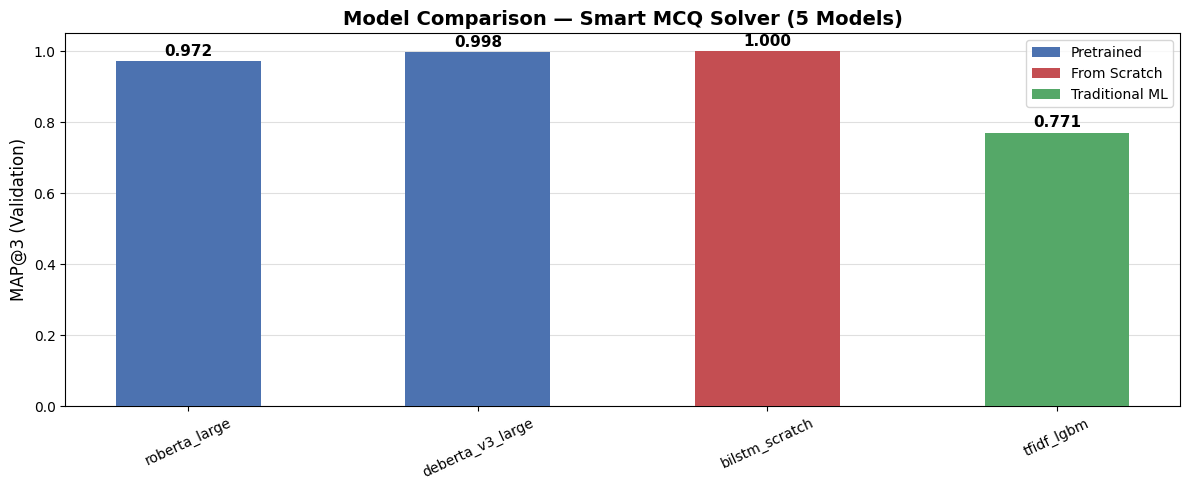

Plot saved → /kaggle/working/model_comparison.png
      Experiment    MAP@3     Model Type
   roberta_large 0.972083     Pretrained
deberta_v3_large 0.997750     Pretrained
  bilstm_scratch 1.000000   From Scratch
      tfidf_lgbm 0.770833 Traditional ML


In [17]:
# ── CELL 14 : Comparison Plot (ALL 5 MODELS) ────────────────
summary_df = pd.DataFrame([
    {'Experiment': k, 'MAP@3': v, 'Model Type': (
        'From Scratch' if k == 'bilstm_scratch' else
        'Traditional ML' if k == 'tfidf_lgbm' else
        'Pretrained'
    )}
    for k, v in run_scores.items()
])

fig, ax = plt.subplots(figsize=(12, 5))
color_map = {
    'Pretrained'      : '#4C72B0',
    'From Scratch'    : '#C44E52',
    'Traditional ML'  : '#55A868',
}
colors = [color_map[t] for t in summary_df['Model Type']]
bars   = ax.bar(summary_df['Experiment'], summary_df['MAP@3'], color=colors, width=0.5, zorder=3)
ax.set_ylabel('MAP@3 (Validation)', fontsize=12)
ax.set_title('Model Comparison — Smart MCQ Solver (5 Models)', fontsize=14, fontweight='bold')
ax.set_ylim(0, 1.05)
ax.grid(axis='y', alpha=0.4, zorder=0)
ax.tick_params(axis='x', rotation=25)
for bar, v in zip(bars, summary_df['MAP@3']):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.015,
            f'{v:.3f}', ha='center', fontsize=11, fontweight='bold')

# Legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#4C72B0', label='Pretrained'),
    Patch(facecolor='#C44E52', label='From Scratch'),
    Patch(facecolor='#55A868', label='Traditional ML'),
]
ax.legend(handles=legend_elements, loc='upper right', fontsize=10)

plt.tight_layout()
plot_path = os.path.join(cfg.output_dir, 'model_comparison.png')
plt.savefig(plot_path, dpi=150)
plt.show()
print(f"Plot saved → {plot_path}")
print(summary_df.to_string(index=False))

In [18]:
# ── CELL 15 : Per-Model Submission Summary ──────────────────
print("\n" + "="*70)
print("SUBMISSION FILES READY FOR DOWNLOAD")
print("="*70)
for f in sorted(os.listdir(cfg.output_dir)):
    if f.startswith('submission'):
        fpath = os.path.join(cfg.output_dir, f)
        size  = os.path.getsize(fpath)
        model = f.replace('submission_', '').replace('.csv', '') if '_' in f else 'ensemble'
        score = run_scores.get(model, None)
        tag   = f" (val MAP@3={score:.4f})" if score else " (ensemble of transformer models)"
        print(f"  📁 {f:45s}  {size:>8,} bytes{tag}")


SUBMISSION FILES READY FOR DOWNLOAD
  📁 submission.csv                                    4,906 bytes (ensemble of transformer models)
  📁 submission_bilstm_scratch.csv                     4,906 bytes (val MAP@3=1.0000)
  📁 submission_deberta_v3_large.csv                   4,906 bytes (val MAP@3=0.9977)
  📁 submission_roberta_large.csv                      4,906 bytes (val MAP@3=0.9721)
  📁 submission_single.csv                             4,906 bytes (ensemble of transformer models)
  📁 submission_tfidf_lgbm.csv                         4,906 bytes (val MAP@3=0.7708)
